[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nattaponm/Teach_RQI_Mosaic_SpatialBias_DualPol/blob/main/notebooks/05_vpr_melting_layer_accumulation.ipynb)

# 05 · ชั้นหลอมเหลว, VPR และการสะสมฝนตามเวลา
*Melting layer, vertical profile of reflectivity and temporal accumulation (advection)*

| | |
|---|---|
| **ระดับ** | 🟢 ป.ตรี ปี 3–4 และ 🔵 ป.โท |
| **เวลาโดยประมาณ** | 90–120 นาที |
| **ควรผ่านมาก่อน** | 04 |
| **ข้อมูลเข้า** | ผลสำเร็จรูป: profile VPR, โมเสค 15 นาที, ผล advection (00 และ 10 UTC) |
| **ผลลัพธ์** | กราฟ VPR และชั้นหลอมเหลว, แผนที่ผลของ VPR, สนามการเคลื่อนที่, เปรียบเทียบ Δt = 1/5/10/15 นาที |

> 📌 **วิธีใช้:** กด *Runtime ▸ Run all* ได้ทันที หรือรันทีละเซลล์ (Shift+Enter) พร้อมอ่านคำอธิบาย
> เซลล์ที่มีหัวข้อ 🔑 เป็นเฉลยที่ซ่อนไว้ ลองทำแบบฝึกหัดก่อนแล้วค่อยเปิดดู

## 🎯 วัตถุประสงค์การเรียนรู้
1. **ระบุ** ความสูงชั้นหลอมเหลว (melting layer, ML) จากโปรไฟล์ ρhv ของเรดาร์โดยไม่ต้องใช้ radiosonde
2. **สร้าง** โปรไฟล์ Z ตามแนวดิ่งแบบ apparent VPR และคำนวณค่าแก้ ΔZ(h)
3. **อธิบาย** ผลของ VPR ต่อพื้นที่ครอบคลุมและปริมาณฝนระยะไกล
4. **เปรียบเทียบ** การสะสมฝนแบบคงค่า 15 นาที (scan-hold) กับแบบแก้การเคลื่อนที่ (advection) ที่ Δt ต่าง ๆ
5. **ประเมิน** ว่าผลของ Δt สำคัญที่สเกลใด (จุด, ลุ่มน้ำย่อย, ลุ่มน้ำใหญ่)

## 1. หลักการ
### 1.1 ชั้นหลอมเหลวและ bright band
เหนือระดับ 0 °C (~4.8–5 กม. ในเขตร้อน) หยาดน้ำฟ้าเป็นหิมะ/น้ำแข็ง (Z ต่ำเพราะ $|K_{ice}|^2 \approx 0.18$)
เมื่อตกลงมาละลาย ผิวเปียกน้ำทำให้ Z สูงขึ้นทันที (**bright band**) และรูปร่างผสมทำให้ **ρhv ลดลงเหลือ 0.90–0.96**
ใต้ชั้นหลอมเหลวเป็นฝน → ρhv กลับมา > 0.97

### 1.2 Apparent VPR และการแก้
ลำคลื่นระยะไกลอยู่สูง ถ้าวัดในหิมะ ค่า Z จะต่ำกว่าที่พื้น → ฝนต่ำกว่าจริง (หรือหายไป)
ใช้ค่ามัธยฐาน Z ในแต่ละชั้นความสูง 200 ม. จากทุกเรดาร์/ทุกมุมยก (Germann & Joss 2002 แนวคิด "apparent VPR"):

$$\Delta Z(h) = Z_{ref} - Z_{VPR}(h), \qquad Z_{ref} = \operatorname{median}\,Z_{VPR}(0.5\text{–}2\ \text{km}), \qquad Z_{corr} = Z_{obs} + \Delta Z(h)$$

แก้เฉพาะเหนือขอบล่าง ML และจำกัด ΔZ ≤ +12 dB จุดที่ "ไม่มีสัญญาณเหนือ ML" ถือว่า **ไม่ทราบค่า** (ไม่ใช่ 0 มม.) เพราะลำคลื่นอาจลอยข้ามฝนไป (overshooting)

### 1.3 การสะสมตามเวลาและ advection
สแกนทุก 15 นาที ถ้าพายุเคลื่อนที่ 10 m/s จะเคลื่อนไป 9 กม. ระหว่างสแกน การถือว่าฝนคงที่ (scan-hold) ทำให้เกิด "รอยกระโดด"
แก้ด้วยการประมาณสนามการเคลื่อนที่ $\mathbf{V}$ (optical flow) แล้วแทรกค่าระหว่างสแกน (Anagnostou & Krajewski 1999):

$$R(\mathbf{x}, \alpha) = (1-\alpha)\,R_0(\mathbf{x} - \alpha\mathbf{V}) + \alpha\,R_1(\mathbf{x} + (1-\alpha)\mathbf{V}), \qquad \alpha\in[0,1], \qquad D = \int R\,dt$$

In [1]:
PACKAGES = ('products',)
#@title ⚙️ เตรียมสภาพแวดล้อม (รันเซลล์นี้ก่อนทุกครั้ง) { display-mode: "form" }
import os, sys, subprocess
REPO, OWNER = "Teach_RQI_Mosaic_SpatialBias_DualPol", "nattaponm"
if "google.colab" in sys.modules:
    if not os.path.exists(f"/content/{REPO}"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        f"https://github.com/{OWNER}/{REPO}.git", f"/content/{REPO}"], check=True)
    os.chdir(f"/content/{REPO}")
else:  # running on your own computer: move to the repository root
    while not os.path.exists("config/study_area.yaml") and os.getcwd() != os.path.dirname(os.getcwd()):
        os.chdir("..")
sys.path.insert(0, os.path.abspath("src"))
from radteach import colab
P = colab.setup(packages=PACKAGES)

installing: arm_pyart (about 1–2 minutes the first time) …
downloading teaching_products_v1.zip …
teaching_products_v1.zip ready in /content/Teach_RQI_Mosaic_SpatialBias_DualPol/data/raw
repository : /content/Teach_RQI_Mosaic_SpatialBias_DualPol
Colab      : True
Thai font  : Sarabun
data       : /content/Teach_RQI_Mosaic_SpatialBias_DualPol/data/raw


## 2. โปรไฟล์แนวดิ่ง: Z และ ρhv

00UTC: ML 4800–6600 m  (ρhv dip (min 0.935 at 6500 m)),  Z_ref = 18.9 dBZ
10UTC: ML 4600–6600 m  (ρhv dip (min 0.953 at 5300 m)),  Z_ref = 19.8 dBZ


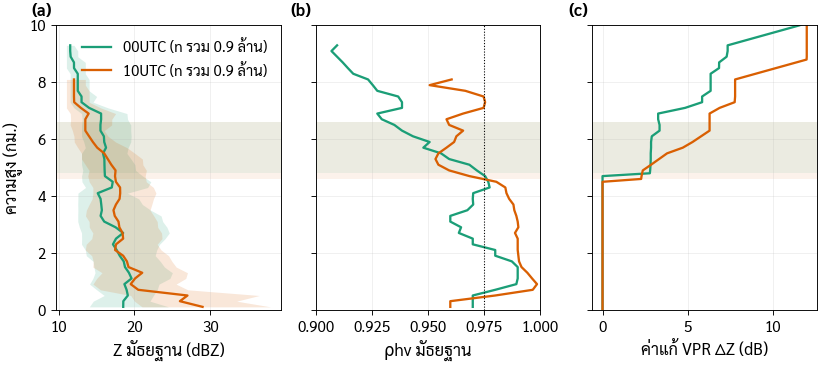

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
trapz = getattr(np, "trapezoid", None) or np.trapz      # NumPy ≥ 2.0 / < 2.0
from radteach import vpr, accum, mosaic, config, plotting as pl, mapping as mp
cfg = config.load_all()
prof = {h: pd.read_csv(P.products / f"mosaic_20241003_{h}_vpr_profile.csv").set_index("h") for h in ["00UTC", "10UTC"]}
mos = {h: np.load(P.products / f"mosaic_20241003_{h}.npz") for h in ["00UTC", "10UTC"]}
fig, axs = pl.subplots(1, 3, width="double", height_mm=85, sharey=True)
col = {"00UTC": "#1b9e77", "10UTC": "#d95f02"}
for h, p in prof.items():
    mb_, mt_, src = vpr.melting_layer(p)
    hg, dz, zref = vpr.correction_table(p, mb_)
    axs[0].plot(p.z_med, p.index / 1e3, color=col[h], label=f"{h} (n รวม {p.n.sum()/1e6:.1f} ล้าน)")
    axs[0].fill_betweenx(p.index / 1e3, p.z_p25, p.z_p75, color=col[h], alpha=0.15, lw=0)
    axs[1].plot(p.rh_med, p.index / 1e3, color=col[h], label=h)
    axs[2].plot(dz, hg / 1e3, color=col[h], label=h)
    for ax in axs:
        ax.axhspan(mb_ / 1e3, mt_ / 1e3, color=col[h], alpha=0.08, lw=0)
    print(f"{h}: ML {mb_:.0f}–{mt_:.0f} m  ({src}),  Z_ref = {zref:.1f} dBZ")
axs[0].set_xlabel("Z มัธยฐาน (dBZ)"); axs[0].set_ylabel(pl.L("height_km")); axs[0].legend(loc="upper right")
axs[1].set_xlabel("ρhv มัธยฐาน"); axs[1].axvline(0.975, color="k", ls=":", lw=0.7); axs[1].set_xlim(0.9, 1.0)
axs[2].set_xlabel("ค่าแก้ VPR ΔZ (dB)")
for ax in axs: ax.set_ylim(0, 10); ax.grid(alpha=0.3, lw=0.4)
pl.panel_labels(axs); pl.save(fig, "05_vpr_profiles"); plt.show()

**แปลผล:** ρhv ต่ำสุดอยู่ที่ราว 5–6.5 กม. ทั้งสองช่วงเวลา → ชั้นหลอมเหลวสูงกว่าละติจูดกลางมาก (2–3 กม.) ตามลักษณะเขตร้อน
Z ลดลงประมาณ 1 dB/กม. ใต้ ML และลดเร็ว 3–4 dB/กม. เหนือ ML — ค่าแก้ VPR จึงสูงถึง +6 ถึง +12 dB สำหรับลำคลื่นที่ 7–9 กม.

> 💡 นี่คือเหตุผลที่ **ไม่จำเป็นต้องใช้ข้อมูล sounding** ในการหา ML สำหรับงานนี้ (ใช้ sounding เป็นตัวตรวจทานได้)

## 3. ผลของ VPR: พื้นที่ที่ได้ข้อมูลเพิ่ม

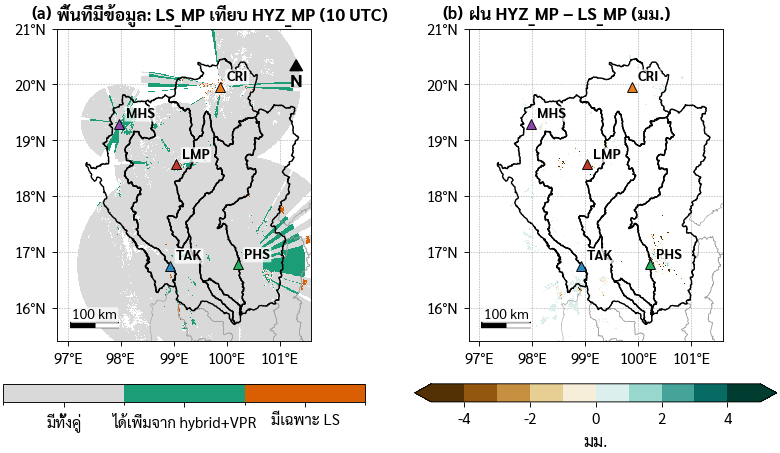

สัดส่วนพื้นที่มีข้อมูลในโดเมน: LS 56.9%  HYZ 59.8%


In [3]:
E = cfg["study_area"]["map_extent"]["north"]
glon, glat = mos["10UTC"]["glon"], mos["10UTC"]["glat"]
ls_, hy_ = mos["10UTC"]["h_LS_MP"], mos["10UTC"]["h_HYZ_MP"]
cat = np.full(ls_.shape, np.nan)
cat[np.isfinite(ls_) & np.isfinite(hy_)] = 0
cat[~np.isfinite(ls_) & np.isfinite(hy_)] = 1
cat[np.isfinite(ls_) & ~np.isfinite(hy_)] = 2
from matplotlib.colors import ListedColormap, BoundaryNorm
fig, axs = pl.subplots(1, 2, width="double", height_mm=105)
cmc = ListedColormap(["#d9d9d9", "#1b9e77", "#d95f02"])
im = mp.show_grid(axs[0], cat, glon, glat, cmc, BoundaryNorm([-0.5, 0.5, 1.5, 2.5], 3))
mp.basemap(axs[0], E, title="พื้นที่มีข้อมูล: LS_MP เทียบ HYZ_MP (10 UTC)", scale_km=100)
cb = fig.colorbar(im, ax=axs[0], orientation="horizontal", ticks=[0, 1, 2], shrink=0.9)
cb.ax.set_xticklabels(["มีทั้งคู่", "ได้เพิ่มจาก hybrid+VPR", "มีเฉพาะ LS"])
d = hy_ - ls_
im2 = mp.show_grid(axs[1], np.where(np.abs(d) > 0.05, d, np.nan), glon, glat, plt.get_cmap("BrBG", 10), plt.Normalize(-5, 5))
mp.basemap(axs[1], E, title="ฝน HYZ_MP − LS_MP (มม.)", scale_km=100, north=False)
fig.colorbar(im2, ax=axs[1], orientation="horizontal", shrink=0.9, extend="both").set_label("มม.")
pl.panel_labels(axs); pl.save(fig, "05_vpr_coverage_gain"); plt.show()
print(f"สัดส่วนพื้นที่มีข้อมูลในโดเมน: LS {100*np.isfinite(ls_).mean():.1f}%  HYZ {100*np.isfinite(hy_).mean():.1f}%")

**แปลผล:** พื้นที่สีเขียวคือบริเวณที่ LS ต้องทิ้งเพราะลำคลื่นอยู่เหนือขอบล่าง ML แต่ HYZ_MP ใช้ได้หลังแก้ VPR (ส่วนใหญ่ระยะ > 120 กม.)
สีส้ม (มีเฉพาะ LS) คือจุดที่ hybrid ตัดสินว่ามุมต่ำสุดเชื่อถือไม่ได้ (บัง/ชิดพื้น/clutter)

## 4. การสะสมฝน: scan-hold กับ advection
ผลสำเร็จรูปคำนวณด้วย `accum.accumulate` ที่ Δt = 1, 5, 10, 15 นาที ทั้งแบบมีการเคลื่อนที่ (ADV) และไม่มี (EUL, แทรกเชิงเส้นในเวลา)

วิธีหาการเคลื่อนที่: pysteps-LK


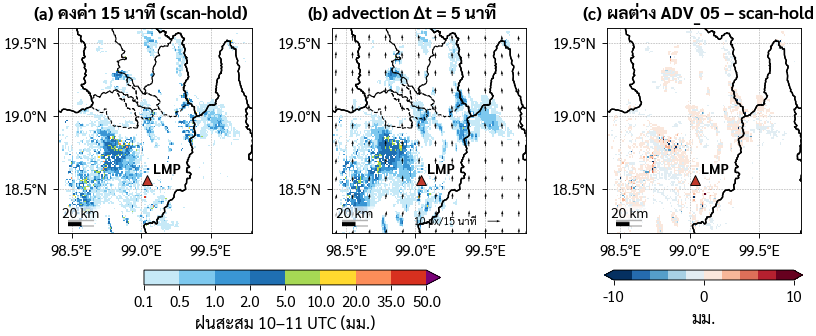

In [4]:
adv = {h: np.load(P.products / f"advection_20241003_{h}.npz", allow_pickle=True) for h in ["00UTC", "10UTC"]}
a = adv["10UTC"]
V = a["V"]; print("วิธีหาการเคลื่อนที่:", a["motion_method"])
Z = [98.4, 99.8, 18.2, 19.6]                # ซูมเชียงใหม่และต้นน้ำปิง
fig, axs = pl.subplots(1, 3, width="double", height_mm=78)
cm, nm = pl.rain_cmap()
for ax, k_, t in [(axs[0], "SCAN_HOLD", "คงค่า 15 นาที (scan-hold)"), (axs[1], "ADV_05", "advection Δt = 5 นาที")]:
    im = mp.show_grid(ax, a[k_], glon, glat, cm, nm)
    mp.basemap(ax, Z, title=t, scale_km=20, north=False, grid_step=0.5, radars=["LMP"],
               subbasins=cfg["study_area"]["ping_headwater_subbasins"])
step = 12
X, Y = np.meshgrid(glon, glat)
q = axs[1].quiver(X[::step, ::step], Y[::step, ::step], V[0][::step, ::step], -V[1][::step, ::step], color="k",
                  scale=150, width=0.004, zorder=20)
axs[1].quiverkey(q, 0.80, 0.06, 10, "10 px/15 นาที", labelpos="W", fontproperties={"size": 7})
d = a["ADV_05"] - a["SCAN_HOLD"]
im3 = mp.show_grid(axs[2], np.where(np.abs(d) > 0.1, d, np.nan), glon, glat, plt.get_cmap("RdBu_r", 10), plt.Normalize(-10, 10))
mp.basemap(axs[2], Z, title="ผลต่าง ADV_05 − scan-hold", scale_km=20, north=False, grid_step=0.5, radars=["LMP"])
fig.colorbar(im, ax=axs[:2], orientation="horizontal", shrink=0.6, extend="max").set_label("ฝนสะสม 10–11 UTC (มม.)")
fig.colorbar(im3, ax=axs[2], orientation="horizontal", shrink=0.9, extend="both").set_label("มม.")
pl.panel_labels(axs); pl.save(fig, "05_advection_chiangmai"); plt.show()

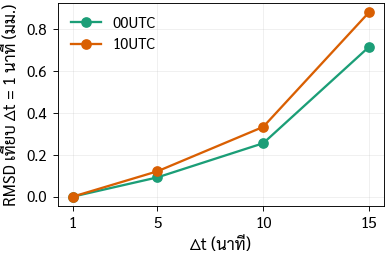

mean_mm           max_mm            rmsd_vs_ADV01       
hour        00UTC 10UTC      00UTC      10UTC         00UTC  10UTC
config                                                            
ADV_01      0.104  0.13  16.531000  16.681000         0.000  0.000
ADV_05      0.104  0.13  17.457001  16.667999         0.092  0.121
ADV_10      0.104  0.13  21.400000  18.691999         0.255  0.333
ADV_15      0.103  0.13  46.042000  42.313000         0.715  0.880
EUL_05      0.103  0.13  46.042000  42.313000         0.715  0.880
EUL_15      0.103  0.13  46.042000  42.313000         0.715  0.880
SCAN_HOLD   0.106  0.13  46.466000  41.437000         0.829  1.071

In [5]:
rows = []
for h, a_ in adv.items():
    ref = a_["ADV_01"]
    for k_ in ["SCAN_HOLD", "EUL_15", "EUL_05", "ADV_15", "ADV_10", "ADV_05", "ADV_01"]:
        v = a_[k_]; m = np.isfinite(v) & np.isfinite(ref) & ((v > 0.1) | (ref > 0.1))
        rows.append(dict(hour=h, config=k_, mean_mm=np.nanmean(v), max_mm=np.nanmax(v),
                         rmsd_vs_ADV01=np.sqrt(np.mean((v[m] - ref[m]) ** 2))))
tab = pd.DataFrame(rows).round(3); tab.to_csv(P.tables / "05_advection_summary.csv", index=False)
fig, ax = pl.subplots(width="single", height_mm=60)
for h in adv:
    t = tab[(tab.hour == h) & tab.config.str.startswith("ADV")]
    ax.plot([int(c[-2:]) for c in t.config], t.rmsd_vs_ADV01, "o-", color=col[h], label=h)
ax.set_xlabel("Δt (นาที)"); ax.set_ylabel("RMSD เทียบ Δt = 1 นาที (มม.)"); ax.set_xticks([1, 5, 10, 15]); ax.grid(alpha=0.3, lw=0.4); ax.legend()
pl.save(fig, "05_rmsd_vs_dt"); plt.show()
tab.pivot(index="config", columns="hour", values=["mean_mm", "max_mm", "rmsd_vs_ADV01"])

**แปลผล:**
- **ค่าเฉลี่ยทั้งโดเมนแทบไม่เปลี่ยน** (มวลน้ำถูกย้ายที่ ไม่ได้เพิ่มหรือลด)
- **ค่าสูงสุดลดลงมาก** เพราะ scan-hold "ปั๊ม" ฝนหนักไว้ที่ตำแหน่งเดิม 15 นาที → รอยเป็นจุด ๆ
- RMSD ลดลงเร็วเมื่อ Δt ≤ 5 นาที → **Δt = 5 นาทีเพียงพอ** สำหรับผลระดับจุด/ลุ่มน้ำย่อย
- แบบ Eulerian (EUL) ไม่ช่วย เพราะการแทรกเชิงเส้นในเวลาของจุดเดิมเทียบเท่ากับค่าเฉลี่ยของสองสแกน

## 5. 🔵 ทดลองคำนวณ advection เอง (ไม่บังคับ, ~30 วินาที)

In [6]:
RUN_ADVECTION = True   #@param {type:"boolean"}
if RUN_ADVECTION:
    rates = np.nan_to_num(mos["10UTC"]["m15_PHY_DP"] * 4.0)       # mm/15 min → mm/h
    dep, Vs, how = accum.accumulate(rates, T=15, dt=5, advect=True)
    valid = np.all(np.isfinite(mos["10UTC"]["m15_PHY_DP"]), axis=0)
    dep = np.where(valid, dep, np.nan)
    k = np.isfinite(dep) & np.isfinite(adv["10UTC"]["ADV_05"])
    print(f"วิธี: {how} | ค่าสูงสุด {np.nanmax(dep):.1f} มม. | r กับผลสำเร็จรูป = {np.corrcoef(dep[k], adv['10UTC']['ADV_05'][k])[0, 1]:.3f}")

วิธี: opencv-farneback | ค่าสูงสุด 23.5 มม. | r กับผลสำเร็จรูป = 0.990


---
## ✏️ แบบฝึกหัด

### แบบฝึกหัด 1 · 🟢 ป.ตรี

ระบุ **ขอบล่างและขอบบนของชั้นหลอมเหลว** ทั้งสองชั่วโมง ถ้าอุณหภูมิลดลง 6.5 °C/กม. คำนวณอุณหภูมิที่ความสูง 1.5 กม. โดยสมมติให้ระดับ 0 °C อยู่ที่ (ก) ขอบบน ML และ (ข) ขอบล่าง ML + 0.5 กม. แบบใดสมเหตุสมผลกว่าสำหรับภาคเหนือเดือนตุลาคม (~20–24 °C ที่ 1.5 กม.)

In [7]:
# ✏️ เขียนคำตอบของคุณในเซลล์นี้
ml = None   # dict hour -> (bottom_m, top_m)

In [8]:
#@title 🔑 เฉลยข้อ 1 — ลองทำเองก่อน แล้วดับเบิลคลิกเพื่อดูโค้ด { display-mode: "form" }
ml = {h: vpr.melting_layer(p)[:2] for h, p in prof.items()}
for h, (b_, t_) in ml.items():
    Ta = 6.5 * (t_ - 1500) / 1000; Tb = 6.5 * (b_ + 500 - 1500) / 1000
    print(f"{h}: ML {b_:.0f}–{t_:.0f} m → (ก) {Ta:.0f} °C  (ข) {Tb:.0f} °C")
print("(ข) สมเหตุสมผลกว่า: ρhv dip ที่เห็นหนาเกินจริงเพราะลำคลื่นระยะไกลกว้าง 1–3 กม. (beam broadening)")
print("หิมะเริ่มละลายที่ 0 °C และละลายหมดภายใน ~0.5 กม. ใต้ระดับนั้น → ใช้ขอบล่าง + 0.5 กม. ประมาณระดับ 0 °C ได้ดีกว่า (ตรวจทานด้วย sounding เชียงใหม่ 48327)")

00UTC: ML 4800–6600 m → (ก) 33 °C  (ข) 25 °C
10UTC: ML 4600–6600 m → (ก) 33 °C  (ข) 23 °C
(ข) สมเหตุสมผลกว่า: ρhv dip ที่เห็นหนาเกินจริงเพราะลำคลื่นระยะไกลกว้าง 1–3 กม. (beam broadening)
หิมะเริ่มละลายที่ 0 °C และละลายหมดภายใน ~0.5 กม. ใต้ระดับนั้น → ใช้ขอบล่าง + 0.5 กม. ประมาณระดับ 0 °C ได้ดีกว่า (ตรวจทานด้วย sounding เชียงใหม่ 48327)


### แบบฝึกหัด 2 · 🟢 ป.ตรี

จากตารางค่าแก้ VPR ของ 10 UTC ที่ความสูง **7 กม.** ต้องเพิ่ม Z กี่ dB และฝน (Z–R MP, b = 1.6) จะเพิ่มขึ้นกี่เท่า

In [9]:
# ✏️ เขียนคำตอบของคุณในเซลล์นี้
dz7 = None; factor = None

In [10]:
#@title 🔑 เฉลยข้อ 2 — ลองทำเองก่อน แล้วดับเบิลคลิกเพื่อดูโค้ด { display-mode: "form" }
mb_, _, _ = vpr.melting_layer(prof["10UTC"])
hg, dz, _ = vpr.correction_table(prof["10UTC"], mb_)
dz7 = float(np.interp(7000, hg, dz)); factor = 10 ** (dz7 / 16)
print(f"ΔZ(7 km) = {dz7:.1f} dB → ฝนเพิ่ม {factor:.1f} เท่า")

ΔZ(7 km) = 6.6 dB → ฝนเพิ่ม 2.6 เท่า


### แบบฝึกหัด 3 · 🟢 ป.ตรี

ในกรอบซูมเชียงใหม่ `Z` ค่าฝนสูงสุดของ SCAN_HOLD, ADV_15 และ ADV_05 (10 UTC) เท่ากับเท่าใด อธิบายว่าทำไมค่าสูงสุดลดลงแต่ค่าเฉลี่ยแทบไม่เปลี่ยน

In [11]:
# ✏️ เขียนคำตอบของคุณในเซลล์นี้
peaks = None

In [12]:
#@title 🔑 เฉลยข้อ 3 — ลองทำเองก่อน แล้วดับเบิลคลิกเพื่อดูโค้ด { display-mode: "form" }
m = (X >= Z[0]) & (X <= Z[1]) & (Y >= Z[2]) & (Y <= Z[3])
peaks = {k_: (float(np.nanmax(np.where(m, a[k_], np.nan))), float(np.nanmean(np.where(m, a[k_], np.nan))))
         for k_ in ["SCAN_HOLD", "ADV_15", "ADV_05"]}
for k_, (mx, mn) in peaks.items():
    print(f"{k_:10s} max {mx:5.1f} mm  mean {mn:.3f} mm")
print("advection กระจายฝนตามเส้นทางพายุแทนที่จะกองไว้ที่ตำแหน่งสแกน มวลรวมจึงคงเดิมแต่ยอดแหลมหายไป")

SCAN_HOLD  max  41.4 mm  mean 0.249 mm
ADV_15     max  42.3 mm  mean 0.243 mm
ADV_05     max  15.7 mm  mean 0.248 mm
advection กระจายฝนตามเส้นทางพายุแทนที่จะกองไว้ที่ตำแหน่งสแกน มวลรวมจึงคงเดิมแต่ยอดแหลมหายไป


### แบบฝึกหัด 4 · 🔵 ป.โท / ส่วนขยาย

ใช้ **ความเร็วเฉลี่ยค่าเดียว** (ค่าเฉลี่ยของ V ในบริเวณที่มีฝน) แทนสนาม V เต็ม แล้วคำนวณ ADV_05 ใหม่ ต่างจากสนามเต็มมากน้อยเพียงใด สนาม V แบบใดเหมาะกับพายุแบบไหน

In [13]:
# ✏️ เขียนคำตอบของคุณในเซลล์นี้
dep_const = None

In [14]:
#@title 🔑 เฉลยข้อ 4 — ลองทำเองก่อน แล้วดับเบิลคลิกเพื่อดูโค้ด { display-mode: "form" }
rates = np.nan_to_num(mos["10UTC"]["m15_PHY_DP"] * 4.0)
wet = rates[0] > 1
vbar = np.array([V[0][wet].mean(), V[1][wet].mean()])
ny, nx = rates.shape[1:]
xg, yg = np.meshgrid(np.arange(nx, dtype=float), np.arange(ny, dtype=float))
Vc = np.broadcast_to(vbar[:, None, None], (2, ny, nx))
ts = np.arange(0, 60 + 1e-9, 5)
samples = [accum.interp(rates[min(int(t // 15), 3)], rates[min(int(t // 15), 3) + 1], Vc, (t - min(int(t // 15), 3) * 15) / 15, xg, yg) for t in ts]
dep_const = trapz(np.array(samples), ts, axis=0) / 60
ref = adv["10UTC"]["ADV_05"]; k = np.isfinite(ref)
print(f"V เฉลี่ย = ({vbar[0]:.1f}, {vbar[1]:.1f}) px/15 นาที; r กับสนามเต็ม = {np.corrcoef(dep_const[k], ref[k])[0, 1]:.3f}")
print("ความเร็วค่าเดียวเหมาะกับระบบฝนขนาดใหญ่ที่เคลื่อนพร้อมกัน สนามเต็มจำเป็นเมื่อเซลล์ฝนหลายเซลล์เคลื่อนต่างทิศ/หมุน")

V เฉลี่ย = (0.6, -4.4) px/15 นาที; r กับสนามเต็ม = 0.997
ความเร็วค่าเดียวเหมาะกับระบบฝนขนาดใหญ่ที่เคลื่อนพร้อมกัน สนามเต็มจำเป็นเมื่อเซลล์ฝนหลายเซลล์เคลื่อนต่างทิศ/หมุน


---
## 💡 คำถามชวนคิดและต่อยอด
- VPR แบบเดียวทั้งโดเมนเหมาะหรือไม่ ถ้าฝน convective และ stratiform อยู่ในเวลาเดียวกัน (ควรแยก VPR ตามชนิดฝน?)
- ถ้าเรดาร์ของกรมอุตุฯ สแกนทุก 5 นาทีได้ จะคุ้มค่ากว่าการทำ advection หรือไม่
- การทำ advection อาจ "สร้าง" ฝนผิดตำแหน่งเมื่อพายุเกิดใหม่/สลายตัวระหว่างสแกน จะตรวจสอบปัญหานี้กับฝนสถานีได้อย่างไร (notebook 07)
- 🔵 ลองใช้ optical flow แบบอื่นใน pysteps (เช่น DARTS, VET) แล้วเปรียบเทียบ

## 📚 อ้างอิง
- Germann, U. & Joss, J. (2002). Mesobeta profiles to extrapolate radar precipitation measurements above the Alps to the ground level. *J. Appl. Meteor.* 41:542–557.
- Kirstetter, P.-E. et al. (2010). Identification of vertical profiles of reflectivity for correction of volumetric radar data using rainfall classification. *J. Appl. Meteor. Climatol.* 49:2167–2180.
- Anagnostou, E.N. & Krajewski, W.F. (1999). Real-time radar rainfall estimation. Part I. *J. Atmos. Oceanic Technol.* 16:189–197.
- Pulkkinen, S. et al. (2019). Pysteps: an open-source Python library for probabilistic precipitation nowcasting (v1.0). *Geosci. Model Dev.* 12:4185–4219.

In [15]:
#@title 💾 บันทึกผลลัพธ์ขึ้น GitHub (fork ของคุณเอง) { display-mode: "form" }
#@markdown ใส่รหัสนิสิต แล้วรันเซลล์นี้ (ต้องตั้ง Colab Secrets `GITHUB_USER` และ `GITHUB_TOKEN` ก่อน — ดูขั้นตอนใน notebook 00)
STUDENT_ID = ""  #@param {type:"string"}
if STUDENT_ID:
    colab.save_to_fork(STUDENT_ID, message="NB05: results")
else:
    print("ยังไม่ได้ใส่รหัสนิสิต — ข้ามการบันทึก (ผลยังอยู่ในโฟลเดอร์ outputs/ ของ Colab)")

ยังไม่ได้ใส่รหัสนิสิต — ข้ามการบันทึก (ผลยังอยู่ในโฟลเดอร์ outputs/ ของ Colab)
